# Fleet Sizing with Monte Carlo Simulation

Which mix of buses and vans should run a corporate passenger shuttle from 6:00 to 22:00 so that waits stay under 10 minutes, at the lowest daily cost?

**Vehicles:**
- **Bus A**: 37 seats, 6:00 to 17:00 (11 h), $42.60/h, 1 available
- **Bus B**: 31 seats, 8:00 to 14:00 (6 h), $42.60/h, 2 available
- **Van A**: 19 seats, 6:00 to 20:00 (14 h), $24.80/h, 1 available
- **Van B**: 13 seats, 7:00 to 22:00 (15 h), $24.80/h, 3 available

**Constraints:** continuous service from 6:00 to 22:00 and no more vehicles than are available.

**Service target:** a fleet qualifies if the day's average wait is under 10 minutes on at least 95% of simulated days. Meeting the target only on average is not enough, because a fleet whose mean sits just under 10 minutes misses it on many individual days.

In [1]:
import bisect
import os
from itertools import product
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 2026
N_SIMULATIONS = 10_000   # simulated days per fleet
N_INDEPENDENT = 2_000    # days per fleet simulated without common random numbers, to measure the variance reduction
N_SENSITIVITY = 2_000    # days per fleet and demand level in the sensitivity study
WAIT_TARGET = 10         # minutes
SERVICE_LEVEL = 0.95     # share of days that must meet the target
DAY_MINUTES = 960        # 6:00 to 22:00; minute 0 is 6:00

sns.set_style('whitegrid')
os.makedirs("plots", exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150})

def clock(minute):
    return f"{6 + int(minute // 60)}:{int(minute % 60):02d}"

## Vehicles

In [2]:
class VehicleType:
    def __init__(self, name, capacity, start_min, end_min, cost_per_hour, max_available):
        self.name = name
        self.capacity = capacity
        self.start_min = start_min
        self.end_min = end_min
        self.cost_per_hour = cost_per_hour
        self.max_available = max_available

    def hours_worked(self):
        return (self.end_min - self.start_min) / 60

    def daily_cost(self):
        return self.hours_worked() * self.cost_per_hour

    def __repr__(self):
        return f"{self.name} ({self.capacity} seats, {clock(self.start_min)}-{clock(self.end_min)}, ${self.cost_per_hour}/h)"

VEHICLES = [
    VehicleType('Bus A', capacity=37, start_min=0, end_min=660, cost_per_hour=42.6, max_available=1),
    VehicleType('Bus B', capacity=31, start_min=120, end_min=480, cost_per_hour=42.6, max_available=2),
    VehicleType('Van A', capacity=19, start_min=0, end_min=840, cost_per_hour=24.8, max_available=1),
    VehicleType('Van B', capacity=13, start_min=60, end_min=960, cost_per_hour=24.8, max_available=3),
]

# Every individual vehicle is a "slot" with its own random stream, so a given bus
# drives the same schedule on day k in every fleet that includes it.
SLOTS = [(v.name, i) for v in VEHICLES for i in range(v.max_available)]

for v in VEHICLES:
    print(f"{v!r:55} cost/day ${v.daily_cost():7.2f}   available: {v.max_available}")

Bus A (37 seats, 6:00-17:00, $42.6/h)                   cost/day $ 468.60   available: 1
Bus B (31 seats, 8:00-14:00, $42.6/h)                   cost/day $ 255.60   available: 2
Van A (19 seats, 6:00-20:00, $24.8/h)                   cost/day $ 347.20   available: 1
Van B (13 seats, 7:00-22:00, $24.8/h)                   cost/day $ 372.00   available: 3


## Vehicle trips from recorded data

Each vehicle makes its first trip at the start of its shift. After that, the time to its next departure is resampled from real gaps between departures recorded in four time windows (6 to 9, 9 to 14, 14 to 18 and 18 to 22).

In [3]:
class BusArrivalData:
    """Recorded gaps between departures, one array per time window."""

    def __init__(self, data_files):
        windows = sorted(data_files)
        self.window_ends = [end for _, end in windows]
        self.gaps = [pd.read_csv(data_files[w], header=None).squeeze().to_numpy(float) for w in windows]

    def trip_times(self, start, end, rng):
        """Departure times of one vehicle between start and end."""
        times, t = [float(start)], float(start)
        draws, k = rng.random(64), 0
        while True:
            window = min(bisect.bisect_right(self.window_ends, t), len(self.gaps) - 1)
            gaps = self.gaps[window]
            if k == len(draws):
                draws, k = rng.random(64), 0
            t += gaps[int(draws[k] * len(gaps))]
            k += 1
            if t >= end:
                return np.array(times)
            times.append(t)

bus_data = BusArrivalData({
    (0, 180): 'data/glaxo_6-9_full.csv',
    (180, 480): 'data/glaxo_9-2_full.csv',
    (480, 720): 'data/glaxo_2-6_full.csv',
    (720, 960): 'data/glaxo_6-10_full.csv',
})

for (start, end), gaps in zip([(0, 180), (180, 480), (480, 720), (720, 960)], bus_data.gaps):
    print(f"{clock(start):>5}-{clock(end):<5}  {len(gaps)} recorded gaps, mean {gaps.mean():.1f} min, range {gaps.min():.0f}-{gaps.max():.0f} min")

 6:00-9:00   100 recorded gaps, mean 33.3 min, range 22-50 min
 9:00-14:00  100 recorded gaps, mean 34.2 min, range 15-50 min
14:00-18:00  100 recorded gaps, mean 31.2 min, range 20-40 min
18:00-22:00  100 recorded gaps, mean 15.7 min, range 10-30 min


## Passenger arrivals

Passengers arrive as a non-homogeneous Poisson process with a piecewise-constant rate. Within each window the number of arrivals is Poisson and their times are uniform, which samples the process exactly. `demand_scale` multiplies every rate and is used in the sensitivity study.

In [4]:
# (start, end, mean minutes between passengers)
DEMAND_WINDOWS = [
    (0, 120, 3.0),    # 6:00-8:00
    (120, 240, 2.0),  # 8:00-10:00
    (240, 420, 3.0),  # 10:00-13:00
    (420, 660, 1.6),  # 13:00-17:00, afternoon peak
    (660, 960, 2.6),  # 17:00-22:00
]
EXPECTED_PASSENGERS = sum((end - start) / gap for start, end, gap in DEMAND_WINDOWS)

def generate_passenger_arrivals(rng, demand_scale=1.0):
    parts = []
    for start, end, gap in DEMAND_WINDOWS:
        n = rng.poisson(demand_scale * (end - start) / gap)
        parts.append(np.sort(rng.uniform(start, end, n)))
    return np.concatenate(parts)

print(f"Expected passengers per day: {EXPECTED_PASSENGERS:.1f}")

Expected passengers per day: 425.4


## Queueing simulation

All trips of a fleet are merged in time order. Passengers queue first come, first served, and each departing vehicle boards up to its capacity. Passengers still waiting at 22:00 are counted as unserved. The time-average queue length follows from Little's law: total minutes spent waiting divided by the length of the day.

In [5]:
class FleetSimulator:
    def __init__(self, fleet):
        """fleet: dict {VehicleType: quantity}"""
        self.fleet = fleet
        self.slots = [(v, i) for v, q in fleet.items() for i in range(q)]
        self.daily_cost = sum(v.daily_cost() * q for v, q in fleet.items())

    def run(self, arrivals, slot_trips, record_trips=False):
        """Simulates one day. slot_trips maps (vehicle name, index) to that vehicle's departure times."""
        times = np.concatenate([slot_trips[(v.name, i)] for v, i in self.slots])
        caps = np.concatenate([np.full(len(slot_trips[(v.name, i)]), v.capacity) for v, i in self.slots])
        order = np.argsort(times, kind='stable')
        times, caps = times[order], caps[order]

        arrived = np.searchsorted(arrivals, times, side='right')
        head, max_queue, boarded = 0, 0, []
        for a, c in zip(arrived.tolist(), caps.tolist()):
            queue = a - head
            b = queue if queue < c else c
            boarded.append(b)
            head += b
            if queue > max_queue:
                max_queue = queue

        boarded = np.array(boarded)
        waits = np.repeat(times, boarded) - arrivals[:head]
        unserved_minutes = (DAY_MINUTES - arrivals[head:]).sum()
        metrics = {
            'avg_wait': waits.mean(),
            'p95_wait': np.percentile(waits, 95),
            'max_wait': waits.max(),
            'avg_queue': (waits.sum() + unserved_minutes) / DAY_MINUTES,
            'max_queue': max_queue,
            'passengers': len(arrivals),
            'served': head,
            'unserved': len(arrivals) - head,
            'trips': len(times),
        }
        if record_trips:
            names = np.concatenate([[f"{v.name} #{i + 1}"] * len(slot_trips[(v.name, i)]) for v, i in self.slots])[order]
            queue_before = arrived - np.concatenate([[0], np.cumsum(boarded)[:-1]])
            self.trip_log = pd.DataFrame({
                'vehicle': names, 'time': times, 'hour': (6 + times // 60).astype(int),
                'queue_before': queue_before, 'boarded': boarded, 'capacity': caps,
                'occupancy_pct': 100 * boarded / caps,
            })
        return metrics


def day_streams(day, stream=0):
    """Random inputs for one simulated day: passenger generator and one generator per vehicle slot.
    The same day index gives the same inputs to every fleet (common random numbers)."""
    seeds = np.random.SeedSequence([SEED, stream, day]).spawn(1 + len(SLOTS))
    return np.random.default_rng(seeds[0]), {slot: np.random.default_rng(s) for slot, s in zip(SLOTS, seeds[1:])}


def simulate_day(day, demand_scale=1.0, stream=0):
    pax_rng, slot_rngs = day_streams(day, stream)
    arrivals = generate_passenger_arrivals(pax_rng, demand_scale)
    vehicles = {v.name: v for v in VEHICLES}
    slot_trips = {slot: bus_data.trip_times(vehicles[slot[0]].start_min, vehicles[slot[0]].end_min, rng)
                  for slot, rng in slot_rngs.items()}
    return arrivals, slot_trips

## Fleet configurations

In [6]:
def covers_service_day(fleet):
    covered = np.zeros(DAY_MINUTES, bool)
    for v, q in fleet.items():
        if q:
            covered[v.start_min:v.end_min] = True
    return covered.all()

def describe(fleet):
    return ', '.join(f"{q} {v.name}" for v, q in fleet.items() if q)

FLEETS = []
for counts in product(*[range(v.max_available + 1) for v in VEHICLES]):
    fleet = dict(zip(VEHICLES, counts))
    if sum(counts) and covers_service_day(fleet):
        FLEETS.append(fleet)
SIMULATORS = [FleetSimulator(f) for f in FLEETS]

print(f"{len(FLEETS)} fleets cover 6:00-22:00 (out of {np.prod([v.max_available + 1 for v in VEHICLES]) - 1} combinations)")

27 fleets cover 6:00-22:00 (out of 47 combinations)


## Monte Carlo

Every fleet is simulated on the same 10,000 days: day *k* uses the same passenger arrivals and the same vehicle schedules in every fleet. These common random numbers make the differences between fleets far more precise than independent sampling, because the noise from demand cancels when two fleets are compared.

In [7]:
def run_monte_carlo(n_days, demand_scale=1.0, stream=0, common_random_numbers=True):
    """Returns an array of shape (fleets, days, metrics)."""
    out = np.empty((len(FLEETS), n_days, len(METRICS)))
    for day in range(n_days):
        if common_random_numbers:
            inputs = simulate_day(day, demand_scale, stream)
        for f, sim in enumerate(SIMULATORS):
            if not common_random_numbers:
                inputs = simulate_day(day, demand_scale, stream=1000 + f)
            m = sim.run(*inputs)
            out[f, day] = [m[k] for k in METRICS]
    return out

METRICS = ['avg_wait', 'p95_wait', 'max_wait', 'avg_queue', 'max_queue', 'passengers', 'served', 'unserved', 'trips']
col = {k: i for i, k in enumerate(METRICS)}

t0 = perf_counter()
sims = run_monte_carlo(N_SIMULATIONS)
elapsed = perf_counter() - t0
print(f"{len(FLEETS)} fleets x {N_SIMULATIONS:,} days = {sims.shape[0] * sims.shape[1]:,} simulated days in {elapsed:.0f} s "
      f"({1e6 * elapsed / sims.shape[0] / sims.shape[1]:.0f} microseconds per day)")

27 fleets x 10,000 days = 270,000 simulated days in 27 s (99 microseconds per day)


### Summary per fleet

In [8]:
rows = []
for f, fleet in enumerate(FLEETS):
    wait = sims[f, :, col['avg_wait']]
    rows.append({
        'fleet': describe(fleet),
        **{v.name.lower().replace(' ', '_'): q for v, q in fleet.items()},
        'vehicles': sum(fleet.values()),
        'daily_cost': SIMULATORS[f].daily_cost,
        'avg_wait': wait.mean(),
        'avg_wait_ci95': 1.96 * wait.std(ddof=1) / np.sqrt(len(wait)),
        'std_daily_wait': wait.std(ddof=1),
        'p05_daily_wait': np.percentile(wait, 5),
        'p95_daily_wait': np.percentile(wait, 95),
        'share_days_on_target': (wait < WAIT_TARGET).mean(),
        'p95_wait': sims[f, :, col['p95_wait']].mean(),
        'max_wait': sims[f, :, col['max_wait']].mean(),
        'avg_queue': sims[f, :, col['avg_queue']].mean(),
        'max_queue': sims[f, :, col['max_queue']].mean(),
        'trips': sims[f, :, col['trips']].mean(),
        'served': sims[f, :, col['served']].mean(),
        'unserved': sims[f, :, col['unserved']].mean(),
    })
df = pd.DataFrame(rows).sort_values('daily_cost').reset_index(drop=True)
df['meets_target'] = df['share_days_on_target'] >= SERVICE_LEVEL

print(f"Widest 95% confidence interval on a fleet's mean wait: +/- {df['avg_wait_ci95'].max():.3f} min")
print(f"Passengers per day: {sims[:, :, col['passengers']].mean():.1f} (expected {EXPECTED_PASSENGERS:.1f}); "
      f"left unserved at 22:00: {df['unserved'].mean():.2f} on average")

Widest 95% confidence interval on a fleet's mean wait: +/- 0.022 min
Passengers per day: 425.4 (expected 425.4); left unserved at 22:00: 2.29 on average


### Results for every fleet

In [9]:
show = ['fleet', 'daily_cost', 'avg_wait', 'avg_wait_ci95', 'p05_daily_wait', 'p95_daily_wait',
        'share_days_on_target', 'p95_wait', 'avg_queue', 'trips']
print(df[show].to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print(f"\nMean wait under {WAIT_TARGET} min: {(df['avg_wait'] < WAIT_TARGET).sum()} of {len(df)} fleets")
print(f"Under {WAIT_TARGET} min on at least {SERVICE_LEVEL:.0%} of days: {df['meets_target'].sum()} of {len(df)} fleets")

                             fleet  daily_cost  avg_wait  avg_wait_ci95  p05_daily_wait  p95_daily_wait  share_days_on_target  p95_wait  avg_queue  trips
                  1 Van A, 1 Van B      719.20     10.64           0.02            9.37           12.05                  0.22     25.14       4.70  64.76
                  1 Bus A, 1 Van B      840.60     11.73           0.02           10.17           13.76                  0.03     27.70       5.18  55.71
         1 Bus B, 1 Van A, 1 Van B      974.80      9.43           0.01            8.29           10.72                  0.78     22.99       4.17  75.85
                  1 Van A, 2 Van B     1091.20      8.02           0.01            7.00            9.21                  0.99     20.91       3.54 100.05
         1 Bus A, 1 Bus B, 1 Van B     1096.20     10.55           0.02            9.09           12.51                  0.33     26.11       4.66  66.80
         1 Bus A, 1 Van A, 1 Van B     1187.80      8.40           0.01     

## How much the variance reduction buys

To measure the effect of common random numbers, every fleet is simulated again on 2,000 days with independent random inputs. For the comparison that drives the decision (each fleet against the recommended one), the variance of the difference in daily average wait is compared under both schemes.

In [10]:
recommended_idx = df.index[df['meets_target']][0]
recommended_name = df.loc[recommended_idx, 'fleet']
rec_f = next(f for f, fleet in enumerate(FLEETS) if describe(fleet) == recommended_name)

independent = run_monte_carlo(N_INDEPENDENT, common_random_numbers=False)

ratios = []
for f in range(len(FLEETS)):
    if f == rec_f:
        continue
    var_crn = np.var(sims[f, :, col['avg_wait']] - sims[rec_f, :, col['avg_wait']], ddof=1)
    var_ind = np.var(independent[f, :, col['avg_wait']] - independent[rec_f, :, col['avg_wait']], ddof=1)
    ratios.append(var_ind / var_crn)
ratios = np.array(ratios)

wait_rec = sims[rec_f, :, col['avg_wait']]
print(f"Common random numbers: variance of fleet-vs-recommended differences is {np.median(ratios):.1f}x smaller "
      f"(median; range {ratios.min():.1f}x to {ratios.max():.1f}x)")
print(f"So {N_SIMULATIONS:,} paired days are worth about {np.median(ratios) * N_SIMULATIONS:,.0f} independent days per comparison")

Common random numbers: variance of fleet-vs-recommended differences is 2.0x smaller (median; range 1.0x to 9.6x)
So 10,000 paired days are worth about 19,979 independent days per comparison


## Recommendation

In [11]:
cheapest_on_average = df[df['avg_wait'] < WAIT_TARGET].iloc[0]
recommended = df.loc[recommended_idx]
fastest = df.loc[df['avg_wait'].idxmin()]

options = {'Cheapest on average': cheapest_on_average, 'Recommended': recommended, 'Fastest': fastest}
for label, r in options.items():
    print(f"{label:20} {r['fleet']:45} ${r['daily_cost']:8,.2f}/day  wait {r['avg_wait']:.2f} +/- {r['avg_wait_ci95']:.2f} min  "
          f"on target {r['share_days_on_target']:.1%} of days  p95 wait {r['p95_wait']:.1f} min  queue {r['avg_queue']:.1f}")

print(f"\nRecommended vs fastest: ${(fastest['daily_cost'] - recommended['daily_cost']) * 365:,.0f} less per year, "
      f"for {recommended['avg_wait'] - fastest['avg_wait']:.2f} min more average wait")
print(f"Recommended vs cheapest on average: ${(recommended['daily_cost'] - cheapest_on_average['daily_cost']) * 365:,.0f} more per year, "
      f"days on target {cheapest_on_average['share_days_on_target']:.1%} -> {recommended['share_days_on_target']:.1%}")

Cheapest on average  1 Bus B, 1 Van A, 1 Van B                     $  974.80/day  wait 9.43 +/- 0.01 min  on target 78.4% of days  p95 wait 23.0 min  queue 4.2
Recommended          1 Van A, 2 Van B                              $1,091.20/day  wait 8.02 +/- 0.01 min  on target 99.4% of days  p95 wait 20.9 min  queue 3.5
Fastest              1 Bus A, 2 Bus B, 1 Van A, 3 Van B            $2,443.00/day  wait 5.08 +/- 0.01 min  on target 100.0% of days  p95 wait 14.4 min  queue 2.2

Recommended vs fastest: $493,407 less per year, for 2.94 min more average wait
Recommended vs cheapest on average: $42,486 more per year, days on target 78.4% -> 99.4%


## Sensitivity to demand growth

The same study with every arrival rate multiplied by up to 3, again with common random numbers. For each demand level: which fleet is the cheapest that still meets the target on 95% of days, and how does the recommended fleet hold up?

In [12]:
DEMAND_LEVELS = [1.0, 1.25, 1.5, 2.0, 2.5, 3.0]
sens_rows = []
share_by_level = {}
for level in DEMAND_LEVELS:
    s = run_monte_carlo(N_SENSITIVITY, demand_scale=level, stream=int(round(level * 100)))
    share = (s[:, :, col['avg_wait']] < WAIT_TARGET).mean(axis=1)
    share_by_level[level] = share
    ok = [f for f in np.argsort([sim.daily_cost for sim in SIMULATORS]) if share[f] >= SERVICE_LEVEL]
    best = ok[0] if ok else None
    sens_rows.append({
        'demand': f"{level:g}x",
        'fleets_meeting_target': len(ok),
        'cheapest_fleet': describe(FLEETS[best]) if best is not None else 'none',
        'daily_cost': SIMULATORS[best].daily_cost if best is not None else np.nan,
        'avg_wait': s[best, :, col['avg_wait']].mean() if best is not None else np.nan,
        'recommended_avg_wait': s[rec_f, :, col['avg_wait']].mean(),
        'recommended_share_on_target': share[rec_f],
        'recommended_unserved': s[rec_f, :, col['unserved']].mean(),
    })
df_sens = pd.DataFrame(sens_rows)
print(df_sens.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

demand  fleets_meeting_target            cheapest_fleet  daily_cost  avg_wait  recommended_avg_wait  recommended_share_on_target  recommended_unserved
    1x                     21          1 Van A, 2 Van B     1091.20      8.00                  8.00                         1.00                  2.18
 1.25x                     21          1 Van A, 2 Van B     1091.20      8.16                  8.16                         0.99                  2.59
  1.5x                     21          1 Van A, 2 Van B     1091.20      8.44                  8.44                         0.98                  3.08
    2x                     17 1 Bus B, 1 Van A, 2 Van B     1346.80      8.41                  9.67                         0.68                  4.49
  2.5x                     12          1 Van A, 3 Van B     1463.20      8.07                 16.65                         0.01                  5.61
    3x                      8 1 Bus A, 1 Van A, 2 Van B     1559.80      7.96                 

## Plots

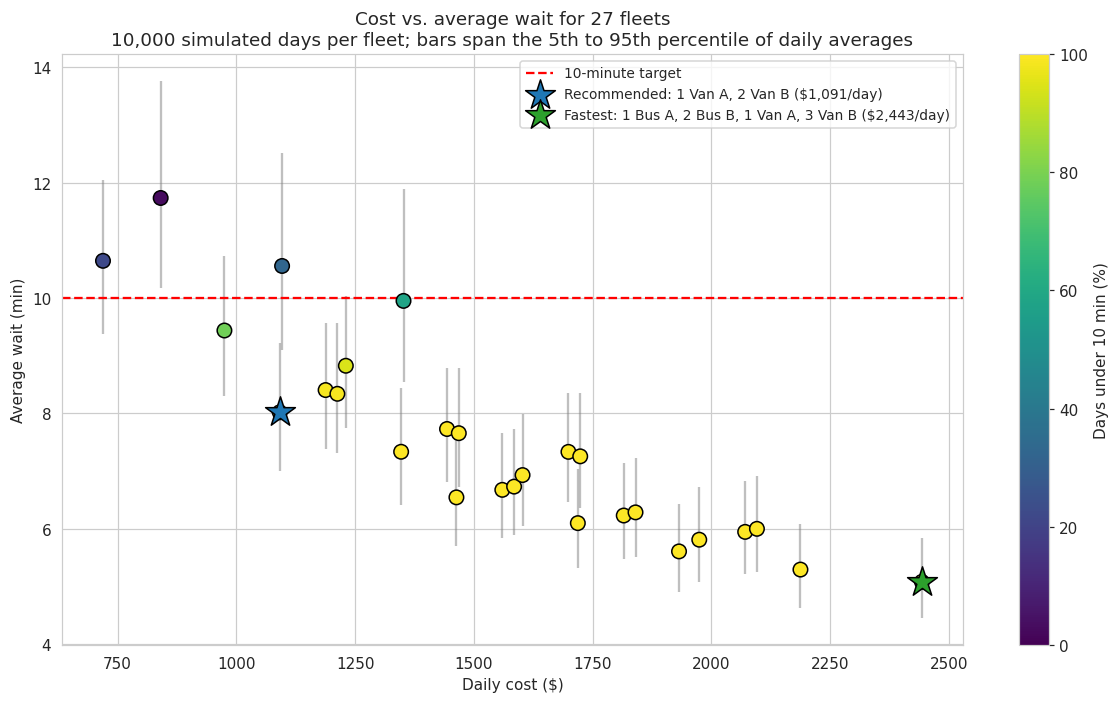

In [13]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sc = ax.scatter(df['daily_cost'], df['avg_wait'], c=100 * df['share_days_on_target'], cmap='viridis',
                vmin=0, vmax=100, s=90, edgecolors='black', zorder=3)
ax.errorbar(df['daily_cost'], df['avg_wait'], yerr=[df['avg_wait'] - df['p05_daily_wait'], df['p95_daily_wait'] - df['avg_wait']],
            fmt='none', ecolor='gray', alpha=0.5, zorder=2)
fig.colorbar(sc, ax=ax, label='Days under 10 min (%)')
ax.axhline(WAIT_TARGET, color='red', ls='--', lw=1.5, label='10-minute target')
for label, r, color in [('Recommended', recommended, 'tab:blue'), ('Fastest', fastest, 'tab:green')]:
    ax.scatter(r['daily_cost'], r['avg_wait'], marker='*', s=420, color=color, edgecolors='black', zorder=4,
               label=f"{label}: {r['fleet']} (${r['daily_cost']:,.0f}/day)")
ax.set_xlabel('Daily cost ($)')
ax.set_ylabel('Average wait (min)')
ax.set_title(f'Cost vs. average wait for {len(df)} fleets\n'
             f'{N_SIMULATIONS:,} simulated days per fleet; bars span the 5th to 95th percentile of daily averages')
ax.legend(loc='upper right', fontsize=9)
fig.tight_layout()
fig.savefig('plots/01_cost_vs_wait.png')
plt.show()

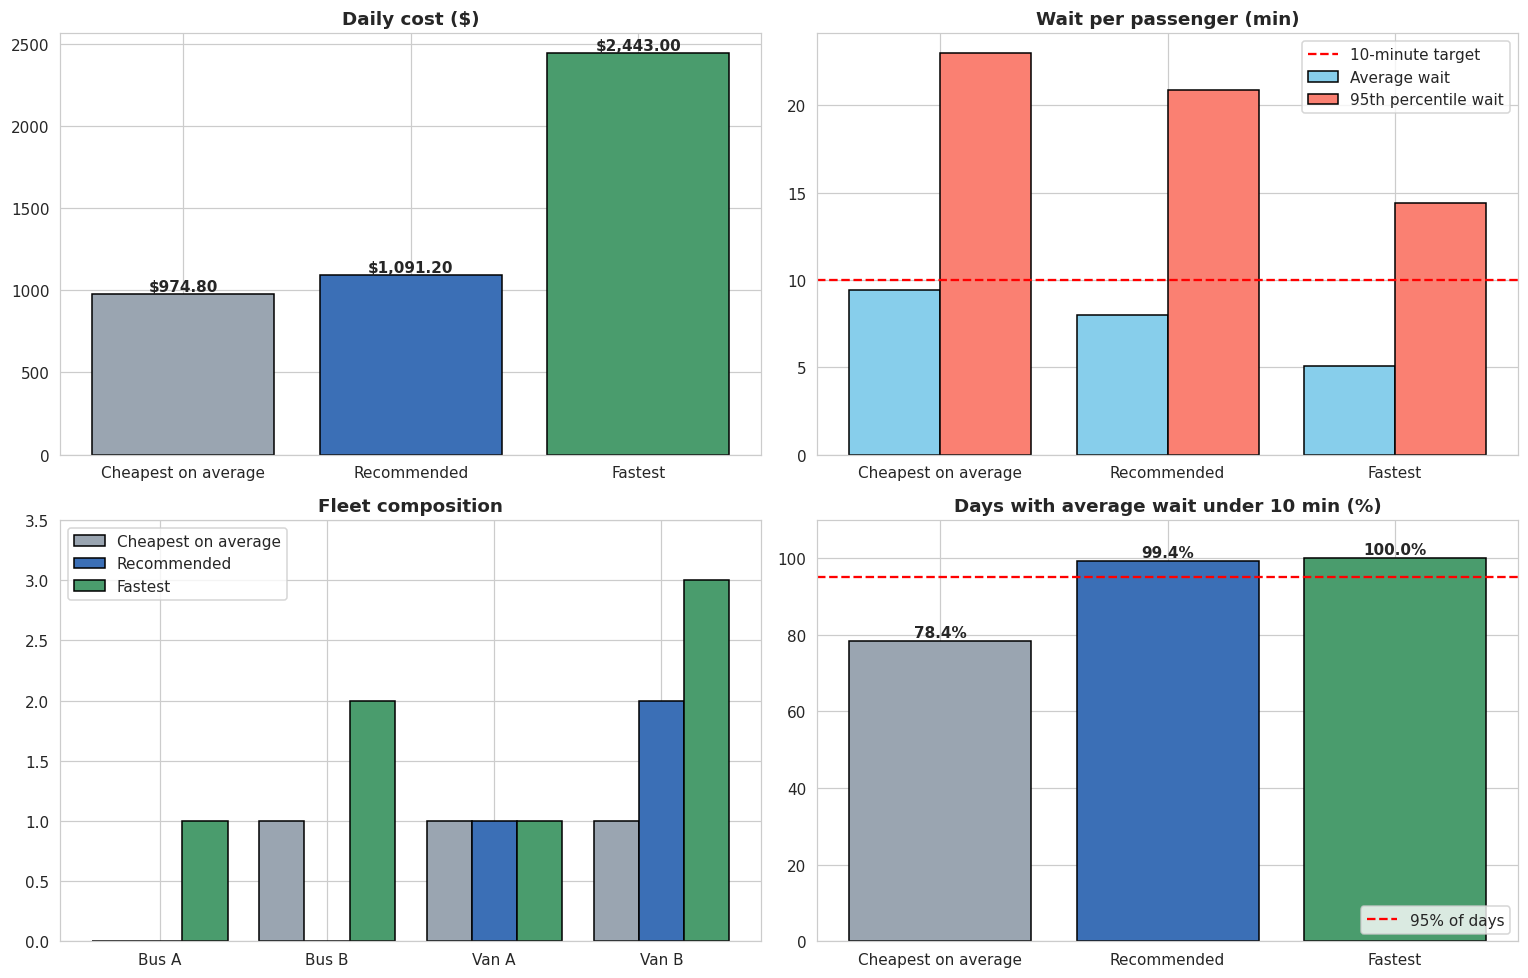

In [14]:
labels = list(options)
rows = list(options.values())
colors = ['#9aa5b1', '#3b6fb6', '#4a9c6d']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].bar(labels, [r['daily_cost'] for r in rows], color=colors, edgecolor='black')
for i, r in enumerate(rows):
    axes[0, 0].text(i, r['daily_cost'] + 20, f"${r['daily_cost']:,.2f}", ha='center', fontweight='bold')
axes[0, 0].set_title('Daily cost ($)', fontweight='bold')

x = np.arange(len(rows))
axes[0, 1].bar(x - 0.2, [r['avg_wait'] for r in rows], 0.4, label='Average wait', color='skyblue', edgecolor='black')
axes[0, 1].bar(x + 0.2, [r['p95_wait'] for r in rows], 0.4, label='95th percentile wait', color='salmon', edgecolor='black')
axes[0, 1].axhline(WAIT_TARGET, color='red', ls='--', label='10-minute target')
axes[0, 1].set_xticks(x, labels)
axes[0, 1].set_title('Wait per passenger (min)', fontweight='bold')
axes[0, 1].legend()

for i, (r, c) in enumerate(zip(rows, colors)):
    axes[1, 0].bar(np.arange(4) + (i - 1) * 0.27, [r['bus_a'], r['bus_b'], r['van_a'], r['van_b']], 0.27,
                   color=c, edgecolor='black', label=labels[i])
axes[1, 0].set_xticks(np.arange(4), [v.name for v in VEHICLES])
axes[1, 0].set_ylim(0, 3.5)
axes[1, 0].set_title('Fleet composition', fontweight='bold')
axes[1, 0].legend()

axes[1, 1].bar(labels, [100 * r['share_days_on_target'] for r in rows], color=colors, edgecolor='black')
axes[1, 1].axhline(100 * SERVICE_LEVEL, color='red', ls='--', label='95% of days')
for i, r in enumerate(rows):
    axes[1, 1].text(i, 100 * r['share_days_on_target'] + 1, f"{r['share_days_on_target']:.1%}", ha='center', fontweight='bold')
axes[1, 1].set_ylim(0, 110)
axes[1, 1].set_title('Days with average wait under 10 min (%)', fontweight='bold')
axes[1, 1].legend(loc='lower right')

fig.tight_layout()
fig.savefig('plots/02_option_comparison.png')
plt.show()

### One simulated day with the recommended fleet

Day 0 of the Monte Carlo, traced trip by trip.

1 Van A, 2 Van B: 101 trips, 389 passengers, average wait 8.10 min, longest queue 17


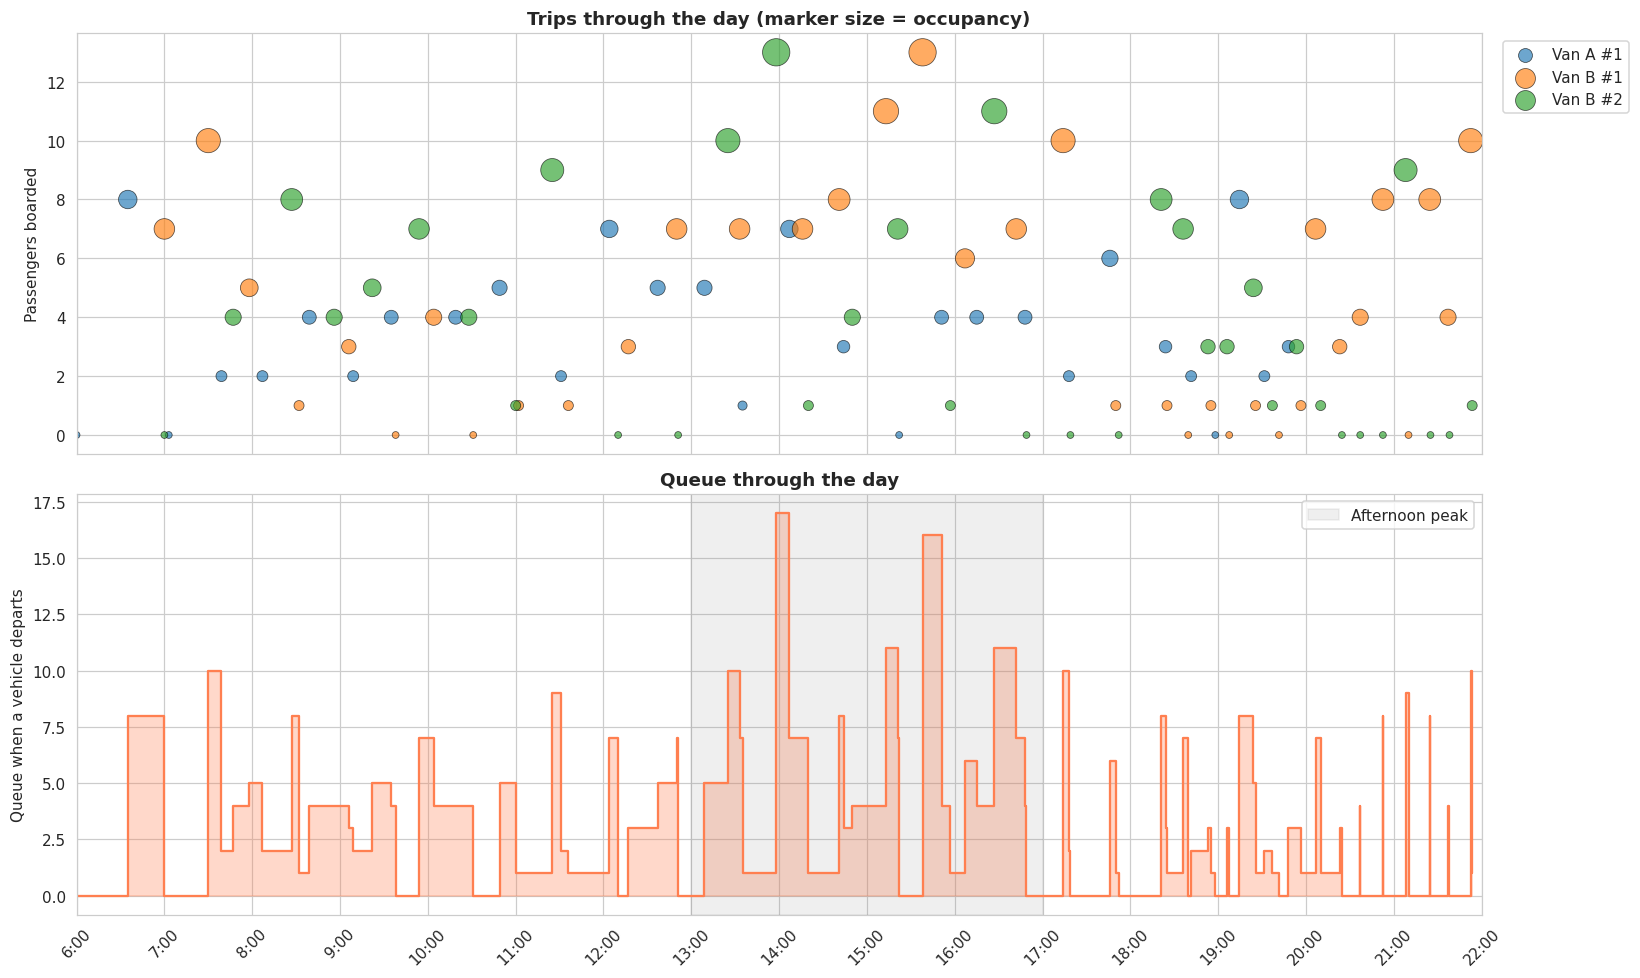

In [15]:
rec_sim = SIMULATORS[rec_f]
day_metrics = rec_sim.run(*simulate_day(0), record_trips=True)
trips = rec_sim.trip_log
print(f"{recommended_name}: {day_metrics['trips']} trips, {day_metrics['served']} passengers, "
      f"average wait {day_metrics['avg_wait']:.2f} min, longest queue {day_metrics['max_queue']}")

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
for name, g in trips.groupby('vehicle'):
    axes[0].scatter(6 + g['time'] / 60, g['boarded'], s=20 + 3 * g['occupancy_pct'], alpha=0.65, edgecolors='black', lw=0.5, label=name)
axes[0].set_ylabel('Passengers boarded')
axes[0].set_title('Trips through the day (marker size = occupancy)', fontweight='bold')
axes[0].legend(bbox_to_anchor=(1.01, 1), loc='upper left')
axes[1].step(6 + trips['time'] / 60, trips['queue_before'], where='post', color='coral')
axes[1].fill_between(6 + trips['time'] / 60, trips['queue_before'], step='post', alpha=0.3, color='coral')
axes[1].axvspan(13, 17, color='gray', alpha=0.12, label='Afternoon peak')
axes[1].set_ylabel('Queue when a vehicle departs')
axes[1].set_title('Queue through the day', fontweight='bold')
axes[1].legend()
axes[1].set_xticks(range(6, 23), [f'{h}:00' for h in range(6, 23)], rotation=45)
axes[1].set_xlim(6, 22)
fig.tight_layout()
fig.savefig('plots/03_daily_timeline.png')
plt.show()

          trips  passengers  occupancy
vehicle                               
Van A #1     29          99       18.0
Van B #1     36         160       34.2
Van B #2     36         130       27.8

Average occupancy per trip: 27.2%  (seats used: 26.2%)


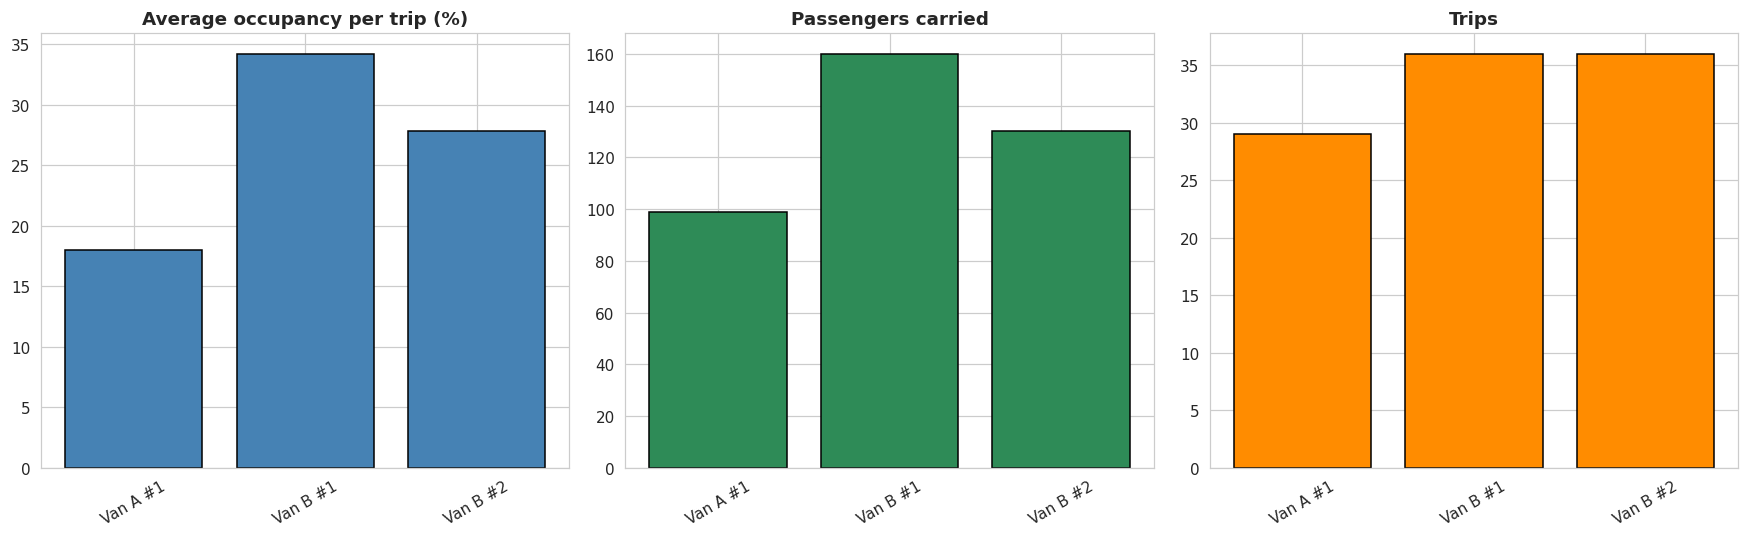

In [16]:
per_vehicle = trips.groupby('vehicle').agg(trips=('time', 'size'), passengers=('boarded', 'sum'), occupancy=('occupancy_pct', 'mean'))
print(per_vehicle.round(1).to_string())
print(f"\nAverage occupancy per trip: {trips['occupancy_pct'].mean():.1f}%  "
      f"(seats used: {trips['boarded'].sum() / trips['capacity'].sum():.1%})")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].bar(per_vehicle.index, per_vehicle['occupancy'], color='steelblue', edgecolor='black')
axes[0].set_title('Average occupancy per trip (%)', fontweight='bold')
axes[1].bar(per_vehicle.index, per_vehicle['passengers'], color='seagreen', edgecolor='black')
axes[1].set_title('Passengers carried', fontweight='bold')
axes[2].bar(per_vehicle.index, per_vehicle['trips'], color='darkorange', edgecolor='black')
axes[2].set_title('Trips', fontweight='bold')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
fig.savefig('plots/04_vehicle_occupancy.png')
plt.show()

Over 500 days: 29.1% average occupancy per trip, 28.6% of seats used

      occupancy  boarded  queue  trips
hour                                  
6         30.12     5.72   5.75   2.19
7         25.73     3.73   3.77   6.21
8         34.82     5.08   5.21   5.70
9         39.16     5.72   5.88   5.40
10        26.92     3.98   4.00   5.27
11        26.28     3.83   3.84   5.25
12        25.25     3.71   3.73   5.30
13        44.67     6.57   6.89   5.24
14        46.01     6.76   7.17   5.55
15        44.87     6.57   6.89   5.78
16        44.83     6.56   6.89   5.76
17        30.39     4.44   4.53   5.79
18        16.91     2.46   2.46   9.96
19        13.88     2.03   2.03  11.45
20        22.43     2.92   2.92   7.59
21        23.72     3.08   3.08   7.63


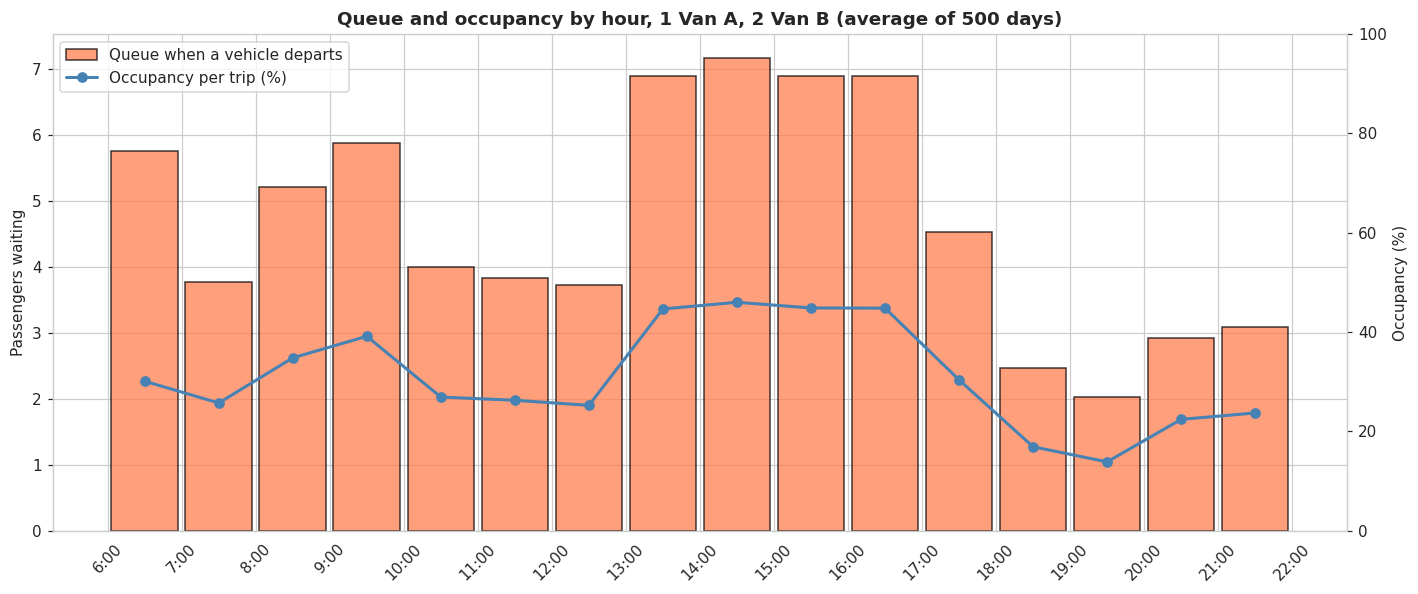

In [17]:
# Hourly view averaged over the first 500 simulated days, so it is not tied to one random day
hourly = []
for day in range(500):
    rec_sim.run(*simulate_day(day), record_trips=True)
    hourly.append(rec_sim.trip_log)
hourly = pd.concat(hourly)
print(f"Over 500 days: {hourly['occupancy_pct'].mean():.1f}% average occupancy per trip, "
      f"{hourly['boarded'].sum() / hourly['capacity'].sum():.1%} of seats used\n")
hourly = hourly.groupby('hour').agg(occupancy=('occupancy_pct', 'mean'), boarded=('boarded', 'mean'),
                                               queue=('queue_before', 'mean'), trips=('time', 'size'))
hourly['trips'] /= 500
print(hourly.round(2).to_string())

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(hourly.index + 0.5, hourly['queue'], width=0.9, color='coral', edgecolor='black', alpha=0.75, label='Queue when a vehicle departs')
ax.set_ylabel('Passengers waiting')
ax2 = ax.twinx()
ax2.plot(hourly.index + 0.5, hourly['occupancy'], 'o-', color='steelblue', lw=2, label='Occupancy per trip (%)')
ax2.set_ylabel('Occupancy (%)')
ax2.set_ylim(0, 100)
ax2.grid(False)
ax.set_xticks(range(6, 23), [f'{h}:00' for h in range(6, 23)], rotation=45)
ax.set_title(f'Queue and occupancy by hour, {recommended_name} (average of 500 days)', fontweight='bold')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')
fig.tight_layout()
fig.savefig('plots/05_hourly_profile.png')
plt.show()

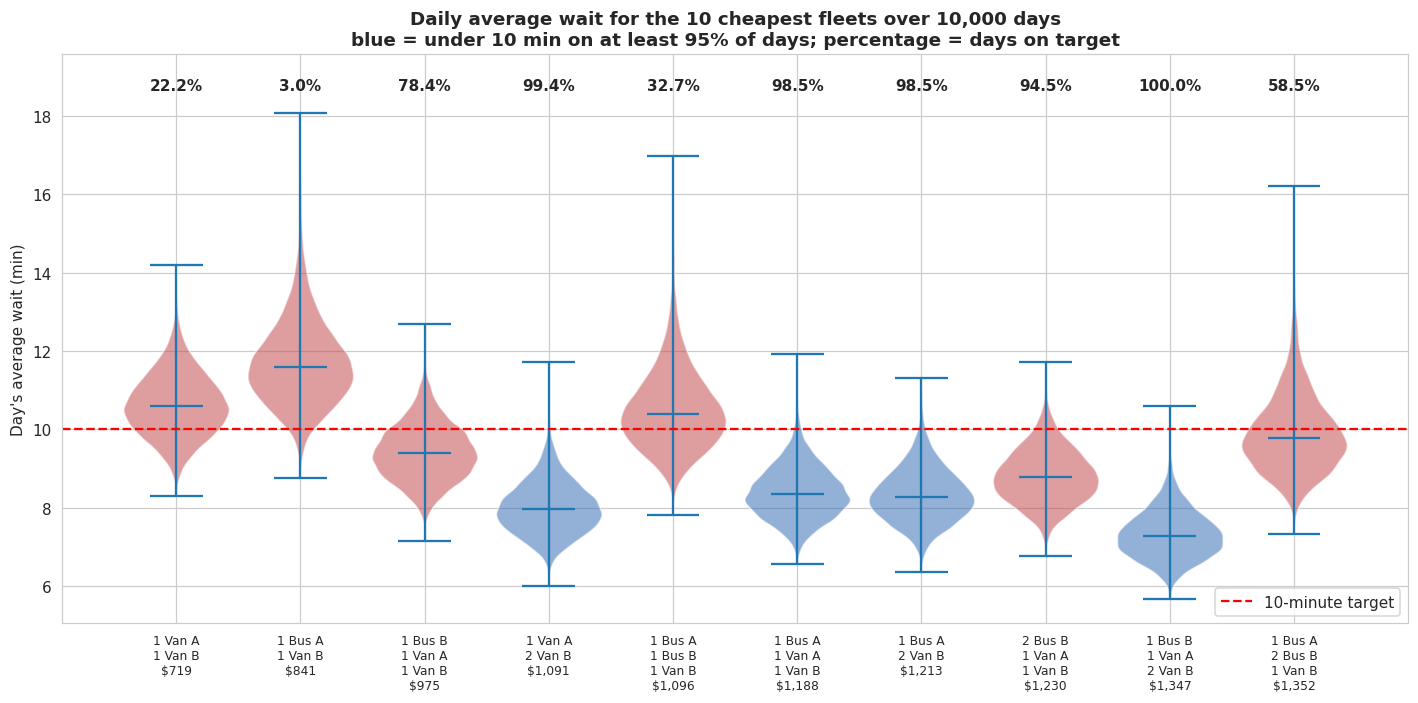

In [18]:
top = df.head(10)
data = [sims[next(f for f, fl in enumerate(FLEETS) if describe(fl) == name), :, col['avg_wait']] for name in top['fleet']]
fig, ax = plt.subplots(figsize=(13, 6.5))
parts = ax.violinplot(data, showmedians=True, widths=0.85)
for body, ok in zip(parts['bodies'], top['meets_target']):
    body.set_facecolor('#3b6fb6' if ok else '#c44e52')
    body.set_alpha(0.55)
ax.axhline(WAIT_TARGET, color='red', ls='--', label='10-minute target')
ax.set_xticks(range(1, len(top) + 1), [f"{n}\n${c:,.0f}" for n, c in zip(top['fleet'].str.replace(', ', '\n'), top['daily_cost'])], fontsize=8)
top_y = max(d.max() for d in data)
ax.set_ylim(top=top_y + 1.5)
for i, s in enumerate(top['share_days_on_target'], 1):
    ax.text(i, top_y + 0.7, f"{s:.1%}", ha='center', va='center', fontsize=10, fontweight='bold')
ax.set_ylabel("Day's average wait (min)")
ax.set_title(f'Daily average wait for the 10 cheapest fleets over {N_SIMULATIONS:,} days\n'
             'blue = under 10 min on at least 95% of days; percentage = days on target', fontweight='bold')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig('plots/06_wait_distribution.png')
plt.show()

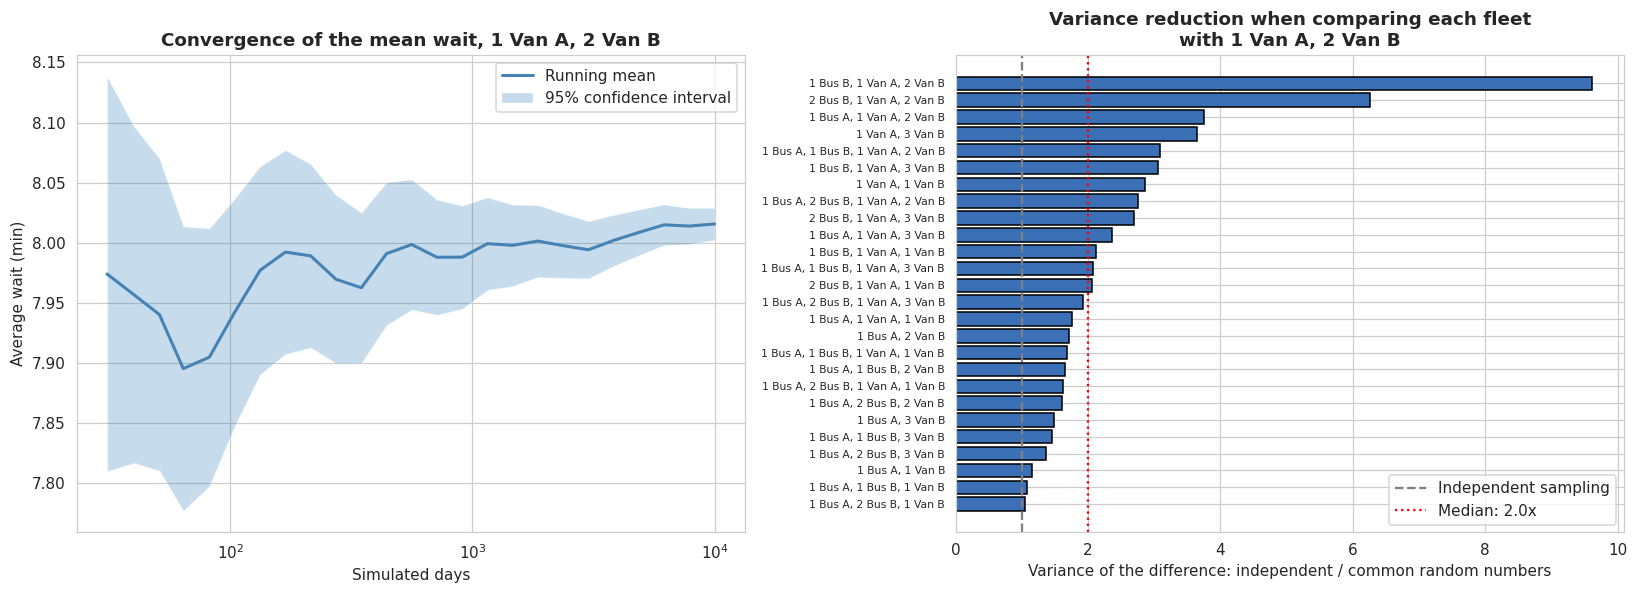

In [19]:
n_grid = np.unique(np.logspace(1.5, np.log10(N_SIMULATIONS), 25).astype(int))
running = [wait_rec[:n].mean() for n in n_grid]
half_width = [1.96 * wait_rec[:n].std(ddof=1) / np.sqrt(n) for n in n_grid]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].plot(n_grid, running, color='steelblue', lw=2, label='Running mean')
axes[0].fill_between(n_grid, np.array(running) - half_width, np.array(running) + half_width, alpha=0.25, label='95% confidence interval')
axes[0].set_xscale('log')
axes[0].set_xlabel('Simulated days')
axes[0].set_ylabel('Average wait (min)')
axes[0].set_title(f'Convergence of the mean wait, {recommended_name}', fontweight='bold')
axes[0].legend()

others = [describe(fl) for f, fl in enumerate(FLEETS) if f != rec_f]
order = np.argsort(ratios)
axes[1].barh(np.arange(len(ratios)), ratios[order], color='#3b6fb6', edgecolor='black')
axes[1].axvline(1, color='gray', ls='--', label='Independent sampling')
axes[1].axvline(np.median(ratios), color='red', ls=':', label=f'Median: {np.median(ratios):.1f}x')
axes[1].set_yticks(np.arange(len(ratios)), [others[i] for i in order], fontsize=7)
axes[1].set_xlabel('Variance of the difference: independent / common random numbers')
axes[1].set_title(f'Variance reduction when comparing each fleet\nwith {recommended_name}', fontweight='bold')
axes[1].legend(loc='lower right')
fig.tight_layout()
fig.savefig('plots/07_monte_carlo_precision.png')
plt.show()

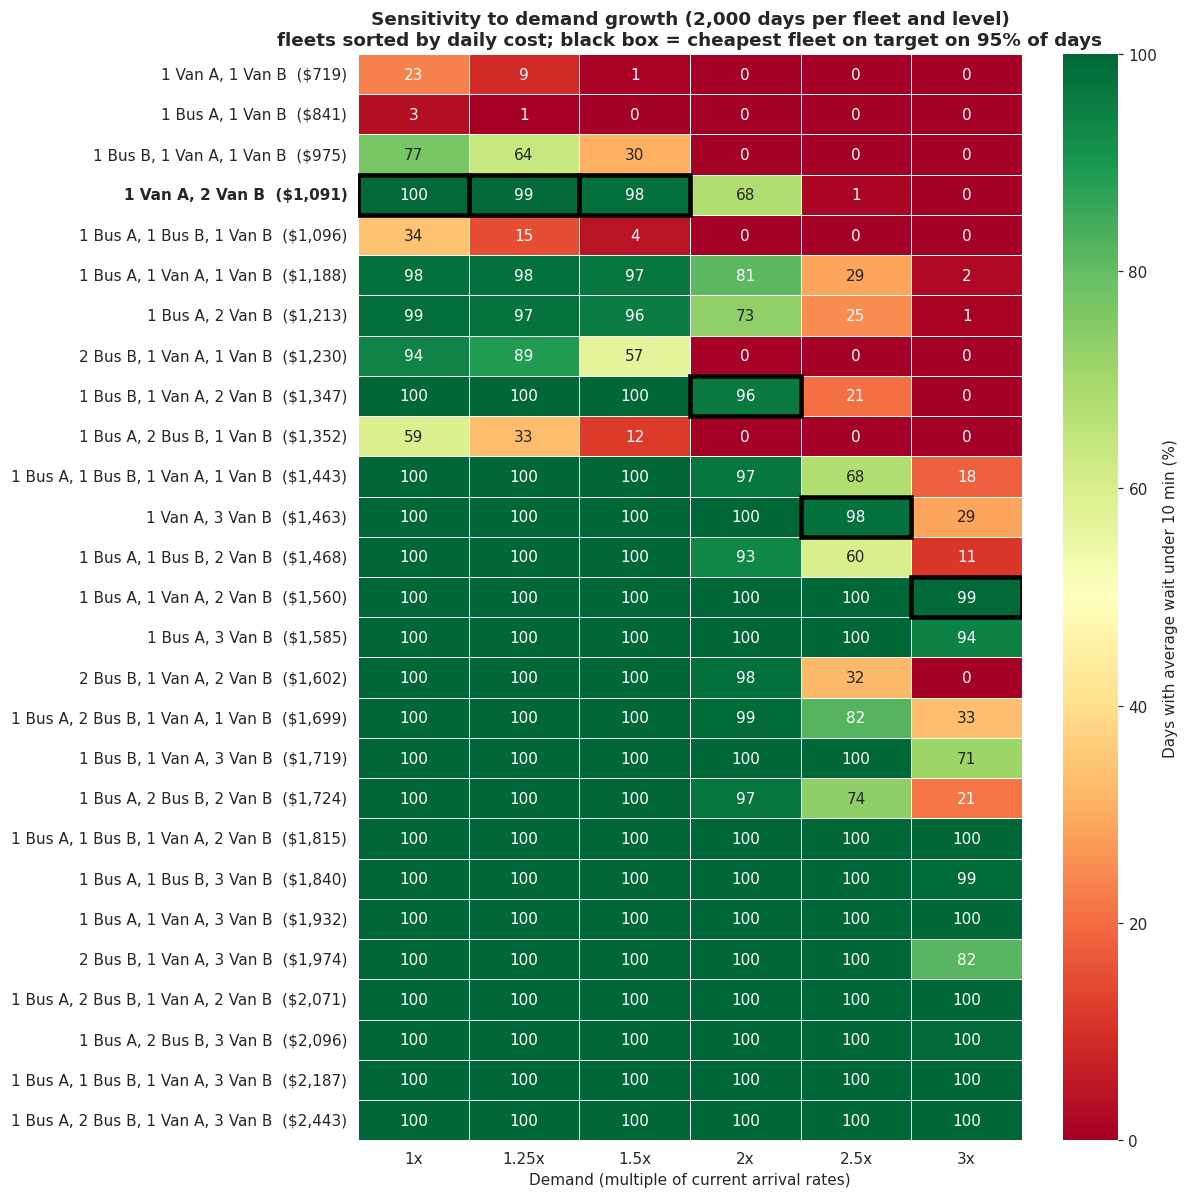

In [20]:
cost_order = np.argsort([sim.daily_cost for sim in SIMULATORS])
grid = np.array([100 * share_by_level[level][cost_order] for level in DEMAND_LEVELS]).T
names = [f"{describe(FLEETS[f])}  (${SIMULATORS[f].daily_cost:,.0f})" for f in cost_order]

fig, ax = plt.subplots(figsize=(11, 11))
sns.heatmap(grid, annot=True, fmt='.0f', cmap='RdYlGn', vmin=0, vmax=100, cbar_kws={'label': 'Days with average wait under 10 min (%)'},
            xticklabels=[f"{level:g}x" for level in DEMAND_LEVELS], yticklabels=names, linewidths=0.5, ax=ax)
for j, level in enumerate(DEMAND_LEVELS):
    ok = [i for i, f in enumerate(cost_order) if share_by_level[level][f] >= SERVICE_LEVEL]
    if ok:
        ax.add_patch(plt.Rectangle((j, ok[0]), 1, 1, fill=False, edgecolor='black', lw=3))
rec_row = list(cost_order).index(rec_f)
ax.get_yticklabels()[rec_row].set_fontweight('bold')
ax.set_xlabel('Demand (multiple of current arrival rates)')
ax.set_ylabel('')
ax.set_title(f'Sensitivity to demand growth ({N_SENSITIVITY:,} days per fleet and level)\n'
             'fleets sorted by daily cost; black box = cheapest fleet on target on 95% of days', fontweight='bold')
fig.tight_layout()
fig.savefig('plots/08_demand_sensitivity.png')
plt.show()

## Export

In [21]:
df.to_csv('data/fleet_results.csv', index=False, float_format='%.4f')
df_sens.to_csv('data/demand_sensitivity.csv', index=False, float_format='%.4f')
print(f"Saved data/fleet_results.csv ({len(df)} fleets) and data/demand_sensitivity.csv")

Saved data/fleet_results.csv (27 fleets) and data/demand_sensitivity.csv
